# 21 — E1b: the fluency dial + beam × aligned mean

Two E1 follow-ups in one factorial sweep, all under **beam search** (the E1-winning recipe), k=4 / steps=24 / 20 prompts per cell:

1. **Fluency-aware selection (λ sweep):** selection score = cumulative concept score + λ · cumulative token log-probability, λ ∈ {0, 0.1, 0.2, 0.4, 1, 2} (the playground showed the knee sits near λ≈1). Question: how much PPL does a unit of expression cost along the dial — can we get inside (or near) the 2.5× guardrail while keeping most of the steering?
2. **beam × aligned mean:** E2/E2b showed the aligned (GPA) mean beats the extrinsic mean under *greedy* decoding below ρ≈0.30. Does that stack with beam search? The λ=0 slice of {extrinsic, aligned} × strata answers it.

Grid: 2 means × 6 λ × 3 ρ strata = 36 cells, 720 records.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4",
    device_map="cuda:0",
    torch_dtype=torch.float16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24
LAMBDAS = (0.0, 0.1, 0.2, 0.4, 1.0, 2.0)
MEANS = ("extrinsic", "aligned")

SELECTION = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())[
    "selected"
]
for stratum, info in SELECTION.items():
    print(f"{stratum:>6}: {info['a']} / {info['b']}  rho={info['rho']:.3f}")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


/home/rodrigo/projects/frh-multi/.venv/lib/python3.11/site-packages/awq/__init__.py:21: DeprecationWarning: 
I have left this message as the final dev message to help you transition.

Important Notice:
- AutoAWQ is officially deprecated and will no longer be maintained.
- The last tested configuration used Torch 2.6.0 and Transformers 4.51.3.
- If future versions of Transformers break AutoAWQ compatibility, please report the issue to the Transformers project.

Alternative:
- AutoAWQ has been adopted by the vLLM Project: https://github.com/vllm-project/llm-compressor

For further inquiries, feel free to reach out:
- X: https://x.com/casper_hansen_
- LinkedIn: https://www.linkedin.com/in/casper-hansen-804005170/

  warnings.warn(_FINAL_DEV_MESSAGE, category=DeprecationWarning, stacklevel=1)


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

2026-07-09 10:56:43.733 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4


2026-07-09 10:56:43.735 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 5462 Mb


   low: sadness.n.01 / music.n.01  rho=0.187
medium: woman.n.01 / king.n.01  rho=0.321
  high: sorrow.n.01 / sadness.n.01  rho=0.566


In [3]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat(
        "What is the most important thing in the world?", "The most important thing is"
    ),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]

LOG_PATH = Path("resources/21_e1b_fluency.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:02<00:00,  2.35s/it]

100%|██████████| 1/1 [00:02<00:00,  2.36s/it]

baseline ready


In [4]:
for stratum, info in SELECTION.items():
    concept_a = fur.get_concept_cached(info["a"], MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(info["b"], MIN_LEMMAS, MAX_TOKENS)
    synsets = [info["a"], info["b"]]
    concepts = {info["a"]: concept_a, info["b"]: concept_b}

    for mean_method in MEANS:
        guide = Concept.average([concept_a, concept_b], method=mean_method)
        for lam in LAMBDAS:
            torch.cuda.empty_cache()
            texts, probe = fur.generate_with_topk_beam_guide(
                PROMPTS,
                concepts=[guide],
                k=K,
                steps=STEPS,
                fluency_weight=lam,
                batch_size=4,
            )
            harness.evaluate(
                PROMPTS,
                texts,
                synsets,
                config={
                    "stratum": stratum,
                    "rho": info["rho"],
                    "mean": mean_method,
                    "lam": lam,
                    "k": K,
                    "steps": STEPS,
                },
                probe=probe,
                baseline_texts=baseline_texts,
                concepts=concepts,
            )
            print(f"{stratum} / {mean_method} / lam={lam:g}: done")

  0%|          | 0/5 [00:00<?, ?it/s]

 20%|██        | 1/5 [00:10<00:42, 10.59s/it]

 40%|████      | 2/5 [00:23<00:35, 11.84s/it]

 60%|██████    | 3/5 [00:34<00:22, 11.38s/it]

 80%|████████  | 4/5 [00:45<00:11, 11.52s/it]

...

 60%|██████    | 3/5 [00:35<00:23, 11.94s/it]

 80%|████████  | 4/5 [00:47<00:11, 11.95s/it]

100%|██████████| 5/5 [01:00<00:00, 12.34s/it]

100%|██████████| 5/5 [01:00<00:00, 12.19s/it]

high / aligned / lam=2: done


In [5]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == 3 * len(MEANS) * len(LAMBDAS) * len(
    PROMPTS
), "one record per cell per prompt"
assert all(r["expression"] is not None for r in parsed), "metric v2 present everywhere"
print(f"gate: {len(parsed)} records parse, expression logged")

gate: 720 records parse, expression logged


In [6]:
rows = []
for record in parsed:
    config = record["config"]
    info = SELECTION[config["stratum"]]
    expr = record["expression"]
    rows.append(
        {
            "stratum": config["stratum"],
            "rho": config["rho"],
            "mean": config["mean"],
            "lam": config["lam"],
            "prompt": record["prompt"],
            "concept_a": info["a"],
            "concept_b": info["b"],
            "delta_a": expr[info["a"]]["delta"],
            "delta_b": expr[info["b"]]["delta"],
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
        }
    )
results = pd.DataFrame(rows)

for side in ("a", "b"):
    zs = []
    for concept, group in results.groupby(f"concept_{side}")[f"delta_{side}"]:
        z = (group - group.mean()) / (group.std() + 1e-8)
        zs.append(z)
    results[f"z_{side}"] = pd.concat(zs).sort_index()
results["joint_z"] = results[["z_a", "z_b"]].min(axis=1)

summary = (
    results.groupby(["stratum", "rho", "mean", "lam"])
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint_z=("joint_z", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
    )
    .reset_index()
    .sort_values(["rho", "mean", "lam"])
)
summary.to_csv("resources/21_e1b_summary.csv", index=False)
summary.round(4)

,stratum,rho,mean,lam,delta_a,delta_b,joint_z,ppl_ratio,flag_share
12,low,0.1867,aligned,0.0,1.5757,1.3612,-0.1101,5.4350,0.75
13,low,0.1867,aligned,0.1,1.5559,1.4630,0.0098,4.5149,0.75
14,low,0.1867,aligned,0.2,1.3749,1.3837,-0.1743,3.9397,0.70
15,low,0.1867,aligned,0.4,1.1624,1.2513,-0.2679,2.4381,0.50
16,low,0.1867,aligned,1.0,0.6457,0.6724,-0.6699,1.2613,0.00
17,low,0.1867,aligned,2.0,0.4714,0.5517,-0.7372,1.1175,0.00
18,low,0.1867,extrinsic,0.0,1.6353,1.4065,-0.1286,6.2585,0.80
19,low,0.1867,extrinsic,0.1,1.7819,1.6016,0.0514,5.1512,0.70
20,low,0.1867,extrinsic,0.2,1.8044,1.7145,0.1385,5.0262,0.75
21,low,0.1867,extrinsic,0.4,1.3365,1.4619,-0.1939,2.7357,0.55


## Point 2 first: does the aligned mean stack with beam search?

Paired per-prompt joint-z gap (aligned − extrinsic) at each λ and stratum.

In [7]:
wide = results.pivot_table(
    index=["stratum", "rho", "lam", "prompt"], columns="mean", values="joint_z"
).reset_index()
wide["gap"] = wide["aligned"] - wide["extrinsic"]
gaps = (
    wide.groupby(["stratum", "rho", "lam"])["gap"]
    .agg(["mean", "sem"])
    .reset_index()
    .sort_values(["rho", "lam"])
)
print(gaps.round(4).to_string(index=False))

stratum    rho  lam    mean    sem
    low 0.1867  0.0  0.0185 0.0805
    low 0.1867  0.1 -0.0415 0.1026
    low 0.1867  0.2 -0.3128 0.1118
    low 0.1867  0.4 -0.0740 0.1045
    low 0.1867  1.0 -0.0929 0.0785
    low 0.1867  2.0 -0.0745 0.0745
 medium 0.3213  0.0 -0.1995 0.1473
 medium 0.3213  0.1 -0.0791 0.1563
 medium 0.3213  0.2 -0.0566 0.1306
 medium 0.3213  0.4  0.0410 0.0982
 medium 0.3213  1.0  0.0112 0.0808
 medium 0.3213  2.0 -0.0859 0.0546
   high 0.5661  0.0  0.0338 0.0497
   high 0.5661  0.1  0.0374 0.0339
   high 0.5661  0.2  0.0433 0.0586
   high 0.5661  0.4  0.1231 0.0803
   high 0.5661  1.0 -0.0053 0.0147
   high 0.5661  2.0  0.0439 0.0552


## The dial: λ-trajectories on the (fluency, expression) plane

Each line is one mean's λ-trajectory within a stratum (λ=0 at the top-right end). The gray dashed line is the 2.5× PPL guardrail; the × marks the best greedy method from E1 for scale.

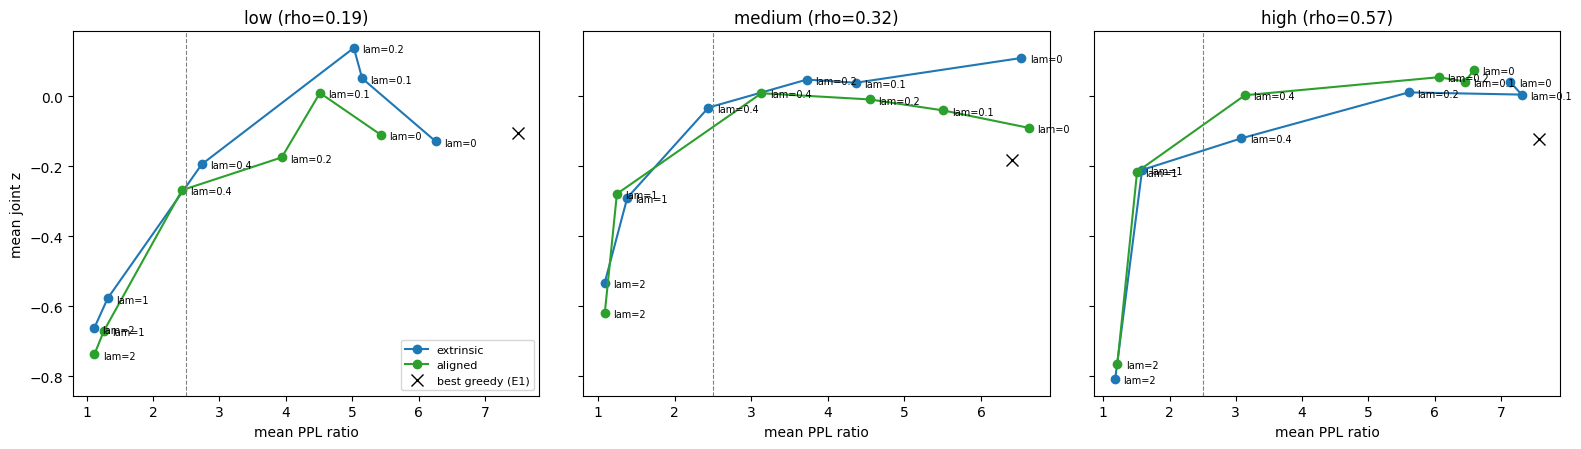

In [8]:
E1_BEST_GREEDY = {  # from resources/20_e1_summary.csv, for visual reference
    "low": (7.50, -0.106),
    "medium": (6.41, -0.183),
    "high": (7.58, -0.122),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
colors = {"extrinsic": "tab:blue", "aligned": "tab:green"}

for ax, (stratum, info) in zip(axes, SELECTION.items()):
    cell = summary[summary["stratum"] == stratum]
    for mean_method in MEANS:
        traj = cell[cell["mean"] == mean_method].sort_values("lam")
        ax.plot(
            traj["ppl_ratio"],
            traj["joint_z"],
            "o-",
            color=colors[mean_method],
            label=mean_method,
        )
        for _, row in traj.iterrows():
            ax.annotate(
                f"lam={row['lam']:g}",
                (row["ppl_ratio"], row["joint_z"]),
                textcoords="offset points",
                xytext=(6, -3),
                fontsize=7,
            )
    ax.plot(
        *E1_BEST_GREEDY[stratum],
        "x",
        color="black",
        markersize=9,
        label="best greedy (E1)",
    )
    ax.axvline(2.5, color="gray", ls="--", lw=0.8)
    ax.set_title(f"{stratum} (rho={info['rho']:.2f})")
    ax.set_xlabel("mean PPL ratio")
axes[0].set_ylabel("mean joint z")
axes[0].legend(fontsize=8)

plt.tight_layout()
plt.savefig("resources/21_e1b_lambda_dial.png", dpi=150)
plt.show()

In [9]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


for stratum in SELECTION:
    for lam in LAMBDAS:
        example = next(
            r
            for r in parsed
            if r["config"]["stratum"] == stratum
            and r["config"]["mean"] == "extrinsic"
            and r["config"]["lam"] == lam
            and "short story" in r["prompt"]
        )
        print(
            f"[{stratum} / extrinsic / lam={lam:g}] ppl_ratio={example['ppl_ratio']:.1f}"
        )
        print("   ", answer(example["text"])[:130])
    print()

[low / extrinsic / lam=0] ppl_ratio=19.4
    Once, a tiny, shimmeringly beautiful bird lived deep in ancient Japan. She flitter-ed and flutter-flutter-ed about the
[low / extrinsic / lam=0.1] ppl_ratio=11.4
    Once, a tiny, delicate key lay forgotten in an old antique shop. For as long its anyone remembered, a beautiful golden lo
[low / extrinsic / lam=0.2] ppl_ratio=6.2
    Once, a tiny, delicate key lay forgotten in a small antique music box. For years, the box remained still and unopened
[low / extrinsic / lam=0.4] ppl_ratio=3.9
    Once, in a quaint little shop in Paris's charming Le Marais neighborhood, a beautiful old violin lay forgotten in a dusty corner
[low / extrinsic / lam=1] ppl_ratio=2.4
    Once, in a small, seaside town, there was a tiny, forgotten shop. It was a small, weathered wooden building
[low / extrinsic / lam=2] ppl_ratio=1.7
    Once, in a small village nestled in the rolling hills of rural France, there was a tiny, mysterious shop called "La Petite

[medium 